In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from scipy.stats import pearsonr
import mar

In [2]:
iyr=1980
fyr=2024
domain='GRf'; domainM='GRp'
var='PRE';units='mm/month'

In [3]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/'
plotsDir='/home/santolam/RECAP/figures/'


In [4]:
model1='MAR'
res1=str('7kmx7km')
nx=ny=10

ds_RF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                            'RF_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['RF']
ds_RF = ds_RF_raw.rename({'TIME': 'time'})
units_RF=ds_RF.units
###
ds_SF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                            'SF_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['SF']
ds_SF = ds_SF_raw.rename({'TIME': 'time'})
units_SF=ds_SF.units

ds_TF=ds_RF+ds_SF



ds1=ds_TF[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr), str(fyr)))


In [5]:
ds_grid= xr.open_dataset('/home/santolam/NST.2014.01.01.00.GRi.nc')
LONS=ds_grid.LON[ny:-ny,nx:-nx].values
LATS=ds_grid.LAT[ny:-ny,nx:-nx].values
dsSH=ds_grid.SH[ny:-ny,nx:-nx]
dsICE=ds_grid.ICE[ny:-ny,nx:-nx]

In [6]:
field1_SH= dsSH.assign_coords({
    'lat': (('y', 'x'), LATS),
    'lon': (('y', 'x'),LONS)
})

In [7]:
field1=ds1.assign_coords({
    'lat': (('Y', 'X'), LATS),
    'lon': (('Y', 'X'),LONS)
})
#field1=field1.rename({"Y":"y","X":"x"})

In [8]:
print(field1_SH.shape,field1.shape)

(62, 96) (540, 62, 96)


In [9]:
###Select the real domain
latS=field1.lat.min(); latN=field1.lat.max()
lonW=field1.lon.min(); lonE=field1.lon.max()


In [10]:
model3='aphro'
res3=str('0.25°x0.25°')

fileName3='APHRO_mon_MA_025deg_V1101_EXR1.1951-2015.nc'
ds3 = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/aphro/monthly/'
                      +fileName3,decode_times=False)['precip']
start_date = pd.Timestamp('1951-01-01')
# Create new time index
nmonths = ds3.time.size
time_new = pd.date_range(start=start_date, periods=nmonths, freq='MS')  # 'MS' = Month Start
# Replace time in dataset
ds3['time'] = time_new
ds3=dom.reversing_lat(ds3)
ds3=ds3.rename({'latitude':'lat','longitude':'lon'})
field3_mm_day=ds3.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_mm_day=field3_mm_day.sel(time=slice(str(iyr),str(fyr)))

# Convert mm/day to mm/month
days_in_month = field3_mm_day['time'].dt.days_in_month
field3= field3_mm_day * days_in_month

field3.shape


(432, 16, 31)

In [11]:
ds3_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_aphro.nc')['elevation']
ds3_SH=ds3_SH_raw.rename({'latitude':'lat','longitude':'lon'})
ds3_SH=dom.reversing_lat(ds3_SH)
field3_SH=ds3_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_SH.shape

(16, 31)

In [12]:
###model 4
model4='gpcp'
res4=str('1.0°x1.0°')

fileName4='precip_mon.gpcp_v2020_1891_2019_10.nc'
ds4= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'
                     +model4+'/'+fileName4)['precip']
print(ds4.attrs) 
#ds4=dom.reversing_lat(ds4)
#units in mm/month -> mm/day

field4=ds4.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))

#month_length = field40.time.dt.days_in_month
#
#field4=field40/month_length
field4=field4.sel(time=slice(str(iyr),str(2019)))
field4.shape


{'long_name': 'gpcc full data monthly product version 2020, precipitation per grid', 'units': 'mm/month', 'code': 20, 'institution': 'DWD'}


(480, 4, 8)

In [13]:
ds4_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_gpcp.nc')['elevation']
#ds4_SH=ds4_SH.rename({'latitude':'lat','longitude':'lon'})

field4_SH=ds4_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [14]:
print(field4.shape,field4_SH.shape)

(480, 4, 8) (4, 8)


In [15]:
#print(field4.lat[0:2],field3.lat[0:2])

In [16]:
model5='cru'
res5=str('0.5°x0.5°')

fileName5='cru_ts4.05.1901.2020.pre.dat.nc'
ds5_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'+model5+'/'+fileName5)['pre']
ds5=dom.reversing_lat(ds5_raw)
field5=ds5.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field5=field5.sel(time=slice(str(iyr),str(2020)))

In [17]:
#field5

In [18]:
ds5_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_cru_hma_grid.nc')['elevation']
ds5_SH=dom.reversing_lat(ds5_SH_raw)
field5_SH=ds5_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))

In [19]:
model6='chirps'
res6='0.05°x0.05°'
fileName6='chirps-v2.0.monthly.nc'
ds6 = xr.open_dataset(sourceData+model6+'/'+fileName6)['precip']
ds6=ds6.rename({'latitude':'lat','longitude':'lon'})
ds6=dom.reversing_lat(ds6)
field6=ds6.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


print(field6.shape)

(531, 78, 158)


In [20]:
ds6_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_chirps_hma_grid.nc')['elevation']
ds6_SH=ds6_SH.rename({'latitude':'lat','longitude':'lon'})
ds6_SH=dom.reversing_lat(ds6_SH)
field6_SH=ds6_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field6_SH.shape

(78, 158)

In [21]:
#field5_SH[:,:].plot()

In [22]:
model7='HARv2'
res7='10kmx10km'
#variable='prcp'
fileName7='HARv2_mon_d10km_d_2d_prcp_1980-2023.nc'
ds7_raw0= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7)['prcp']
ds7_raw=ds7_raw0*24 #mm/h
# Calculate days in each month
days_in_month7= ds7_raw['time'].dt.days_in_month
# Convert to mm/month
ds7= ds7_raw* days_in_month7

def xy_sel_dom(ds,latS,latN,lonW,lonE):
    #latS,latN,lonW,lonE,latlim,lonlim=dom.coord_domain(domain)
    lat_str = ''
    lon_str = ''
    other_dims_str = []
    for dim in ds.coords:
        print(dim)
        if dim in ['lat', 'latitude','LON']:
            lat_str = dim
        elif dim in ['lon', 'longitude','LAT']:
            lon_str = dim
        else:
            other_dims_str.append(dim)
    mask = (
        (latS < ds[lat_str]) & ( ds[lat_str] < latN) 
    & (lonW < ds[lon_str]) & ( ds[lon_str] < lonE)
    )
    field_dom=ds.where(mask,drop=True)
    return field_dom

# Apply mask (non-NaN where the condition is True)
#hgt_subset = hgt.where(mask, drop=True)
field7=xy_sel_dom(ds7.sel(time=slice(str(iyr),str(2023))),latS,latN,lonW,lonE)

time
lon
lat
west_east
south_north


In [23]:
#field7[0,:,:].plot()

In [24]:
fileName7_grF='HARv2_d10km_static_hgt.nc'
ds7_grM= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7_grF)
ds7SH=ds7_grM['hgt'][0,:,:]
#dsSH
field7_SH=xy_sel_dom(ds7SH,latS,latN,lonW,lonE)


time
west_east
south_north
lon
lat


In [25]:

## SAME ANALYSIS BUT FOR multiple data sets(at the same time): lists

dsList=[field1,
        field3,field4,field5,field6,
        field7]
modelList=[model1,
           model3,model4,model5,model6,
           model7]
resList=[res1,
         res3,res4,res5,res6,
         res7]
nameList=list(zip(modelList,resList))

In [26]:
nameList

[('MAR', '7kmx7km'),
 ('aphro', '0.25°x0.25°'),
 ('gpcp', '1.0°x1.0°'),
 ('cru', '0.5°x0.5°'),
 ('chirps', '0.05°x0.05°'),
 ('HARv2', '10kmx10km')]

In [27]:
#elevList=[field1_SH,field3_SH,field4_SH,field5_SH,field6_SH,field7_SH]
#print(len(elevList))

In [28]:
#level_bounds = [(0, 2500), (2500, 4500), (4500, 5500), (5500, 7500)]


In [33]:
def compute_seasonal_means(field, season_months):
    """Compute seasonal and annual means (per year)."""

    month = field['time'].dt.month
    year = field['time'].dt.year
    year_shifted = xr.where(month == 12, year + 1, year)  # Dec → next year

    results = []

    # ---- Seasonal means ----
    for season, months in season_months.items():
        vals = field.sel(time=month.isin(months))
        vals = vals.assign_coords(year=year_shifted.sel(time=vals.time))
        vals_mean = vals.groupby('year').mean('time', skipna=True)
        vals_mean = vals_mean.expand_dims({'season': [season]})
        results.append(vals_mean)

    # ---- Annual mean ----
    ann = field.assign_coords(year=year)
    ann_mean = ann.groupby('year').mean('time', skipna=True)
    ann_mean = ann_mean.expand_dims({'season': ['ANN']})
    results.append(ann_mean)

    return xr.concat(results, dim='season')

seasonList = ['DJF', 'MAM', 'JJA', 'SON','ANN']
season_months = {
    'DJF': [12, 1, 2],
    'MAM': [3,4, 5],
    'JJA': [6, 7, 8],
    'SON': [9,10, 11]
}

In [34]:
#seasonList = ['DJFM', 'AM', 'JJAS', 'ON']
#season_months = {
 #   'DJFM': [12, 1, 2, 3],
 #   'AM': [4, 5],
 #   'JJAS': [6, 7, 8, 9],
 #   'ON': [10, 11]
#}

In [35]:
field1_season_all = compute_seasonal_means(field1, season_months)
field3_season_all = compute_seasonal_means(field3, season_months)
field4_season_all = compute_seasonal_means(field4, season_months)
field5_season_all = compute_seasonal_means(field5, season_months)
field6_season_all = compute_seasonal_means(field6, season_months)
field7_season_all = compute_seasonal_means(field7, season_months)


DJF


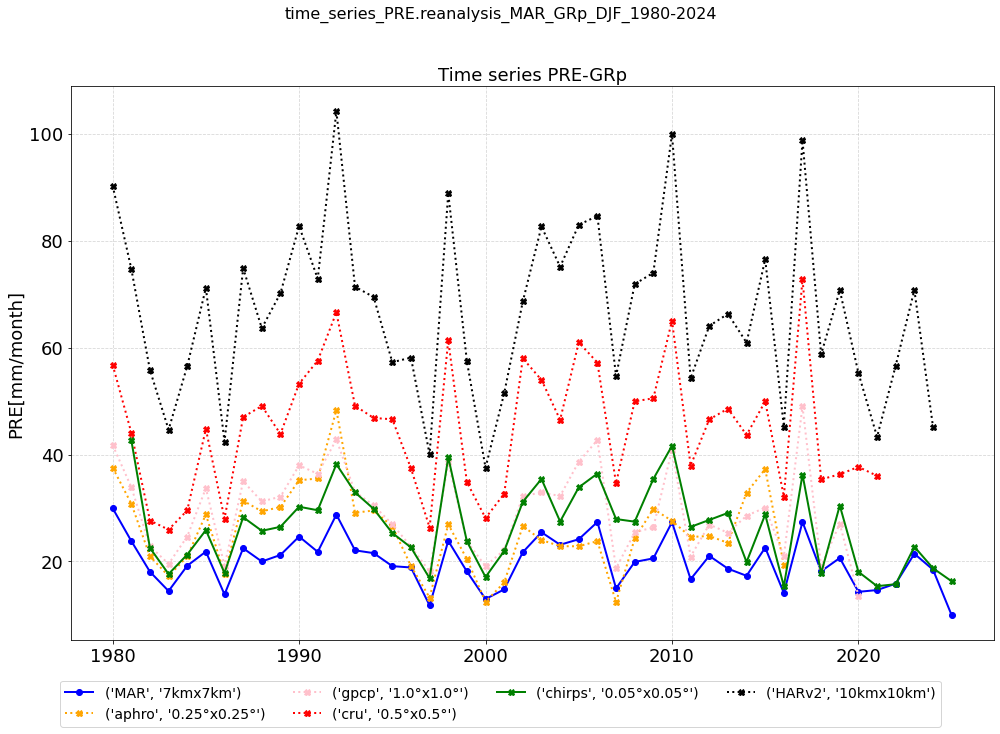

/home/santolam/RECAP/figures/time_series_PRE.reanalysis_MAR_GRp_DJF_1980-2024.png
[19.98320770263672, 25.78572621269234, 29.22016716003418, 45.03096389770508, 26.48779296875, 66.60622714834942]
[4.592784404754639, 7.53460548178885, 8.174166679382324, 11.786531448364258, 7.446143627166748, 16.09927901177503]


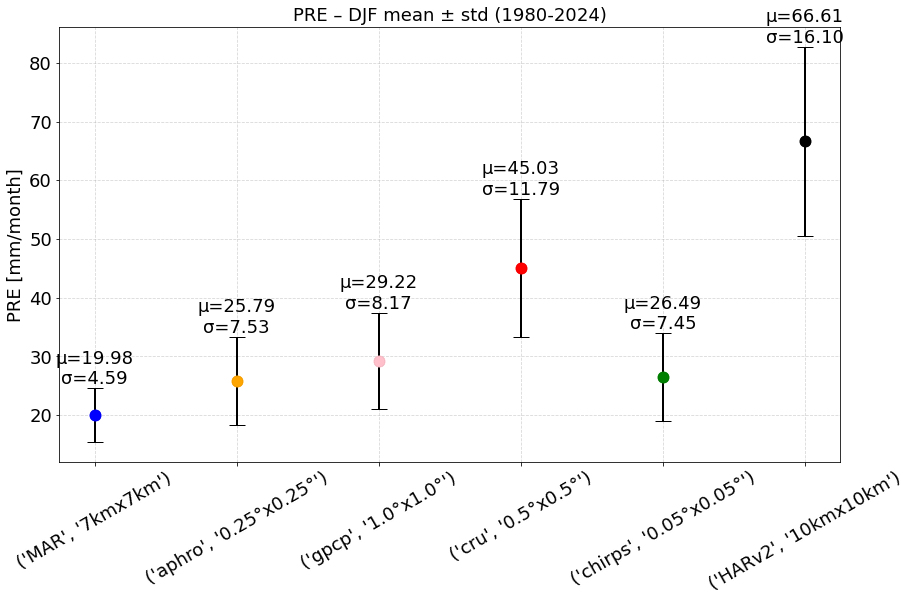

/home/santolam/RECAP/figures/mean_stddev_PRE.reanalysis_MAR_GRp_DJF_1980-2024.png


In [36]:
season=seasonList[0]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList


fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[5], color=colors[5], linewidth=2)

ax.set_title(f'Time series PRE-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
#ax.set_ylim(0,70)
ax.set_title(f'{var} – {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')

MAM


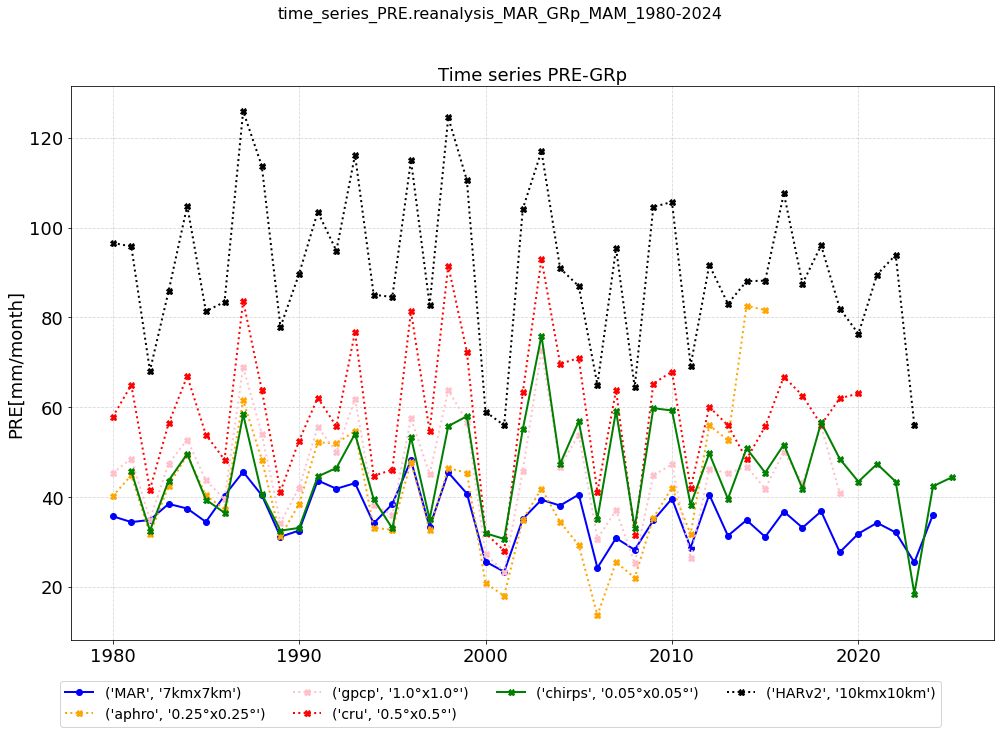

/home/santolam/RECAP/figures/time_series_PRE.reanalysis_MAR_GRp_MAM_1980-2024.png
[35.424251556396484, 41.24530345231576, 45.68274688720703, 58.9123420715332, 45.280879974365234, 90.88377722112911]
[5.731784820556641, 14.776770162522174, 11.16865062713623, 14.713220596313477, 10.52972412109375, 17.33789641953947]


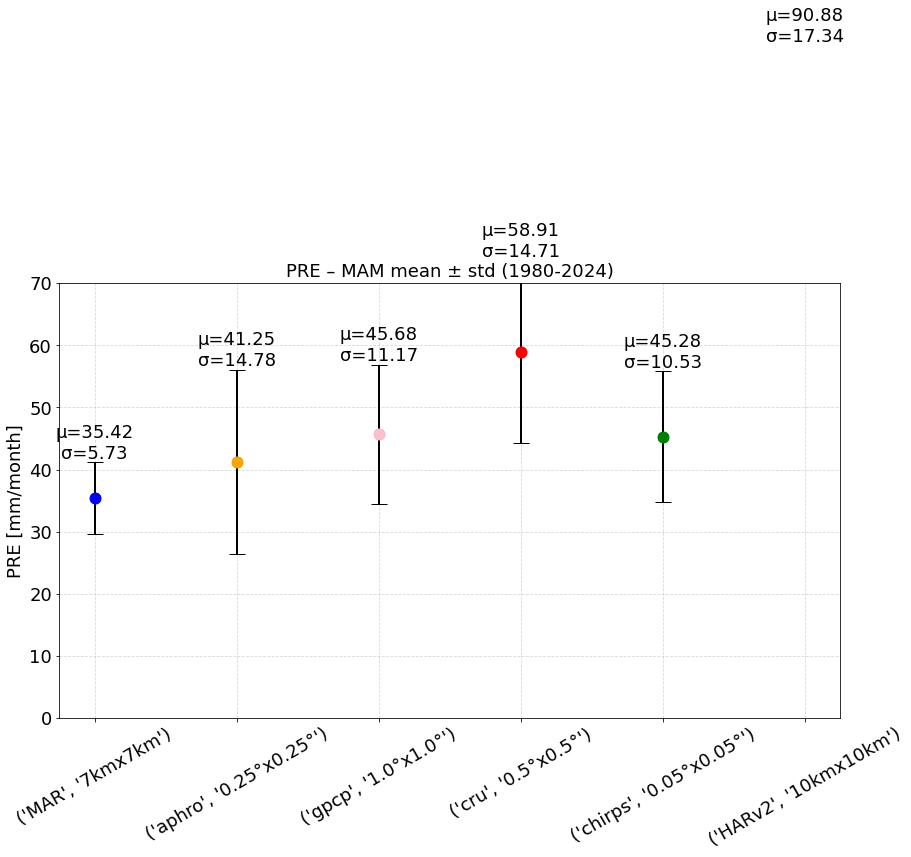

/home/santolam/RECAP/figures/mean_stddev_PRE.reanalysis_MAR_GRp_MAM_1980-2024.png


In [37]:
season=seasonList[1]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList


fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[5], color=colors[5], linewidth=2)

ax.set_title(f'Time series PRE-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
ax.set_ylim(0,70)
ax.set_title(f'{var} – {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')

JJA


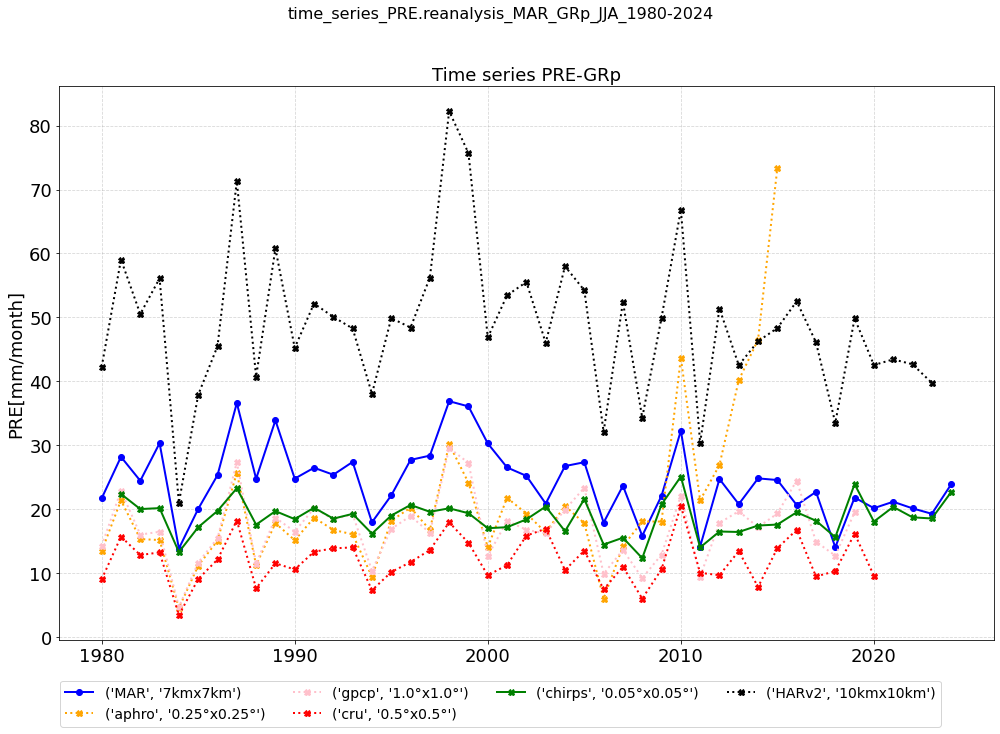

/home/santolam/RECAP/figures/time_series_PRE.reanalysis_MAR_GRp_JJA_1980-2024.png
[24.3239688873291, 20.979061450670017, 17.080745697021484, 11.985334396362305, 18.690900802612305, 48.87458348773435]
[5.533909797668457, 12.554221874244528, 5.202369213104248, 3.550137519836426, 2.675119638442993, 11.397609217891619]


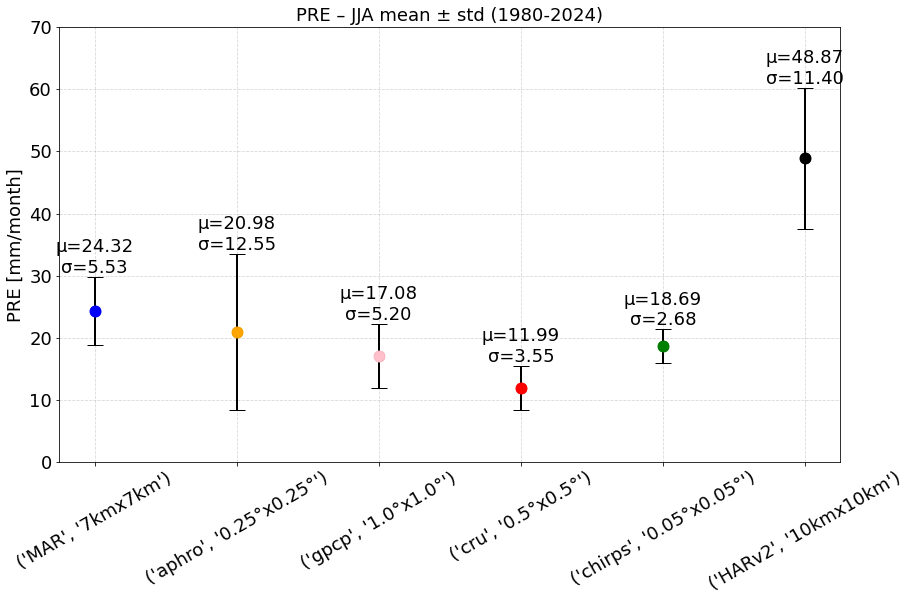

/home/santolam/RECAP/figures/mean_stddev_PRE.reanalysis_MAR_GRp_JJA_1980-2024.png


In [38]:
season=seasonList[2]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList


fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[5], color=colors[5], linewidth=2)

ax.set_title(f'Time series PRE-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
ax.set_ylim(0,70)
ax.set_title(f'{var} – {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')

SON


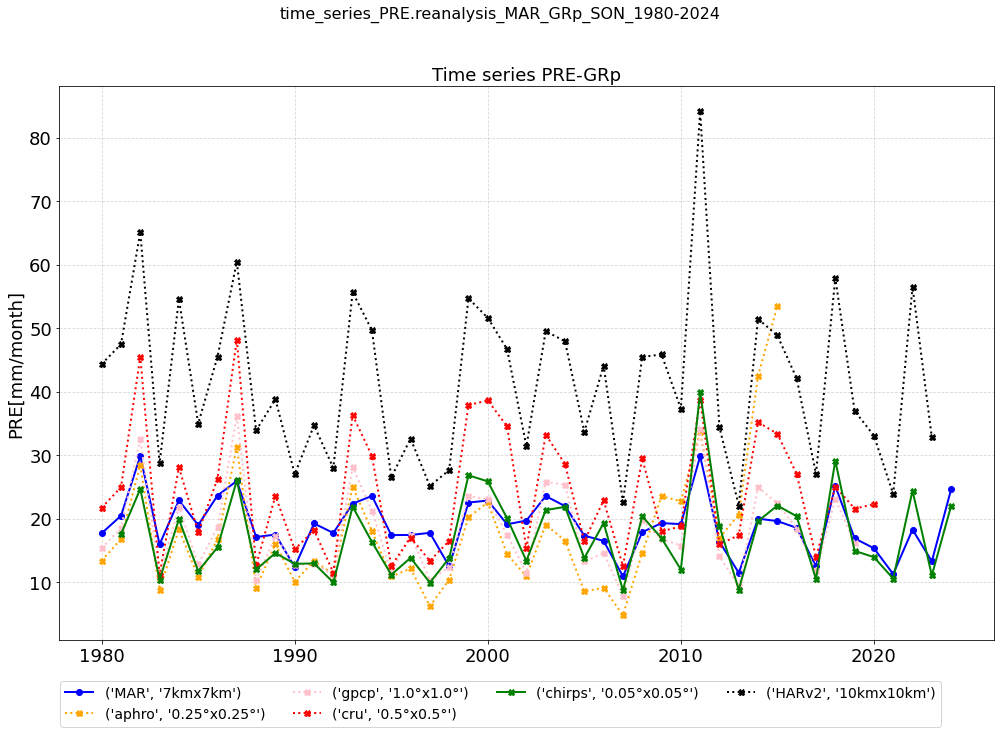

/home/santolam/RECAP/figures/time_series_PRE.reanalysis_MAR_GRp_SON_1980-2024.png
[18.998903274536133, 17.832625306294446, 18.039682388305664, 24.092899322509766, 17.32390785217285, 41.43342607826089]
[4.435064315795898, 9.999704439202072, 6.878477096557617, 9.68807601928711, 6.434274196624756, 13.018873612241663]


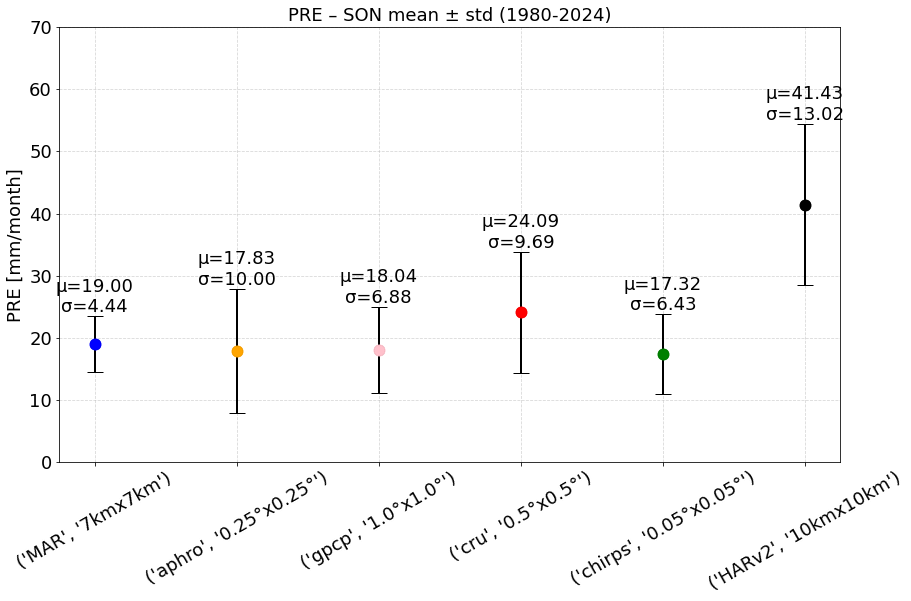

/home/santolam/RECAP/figures/mean_stddev_PRE.reanalysis_MAR_GRp_SON_1980-2024.png


In [39]:
season=seasonList[3]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList

fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[5], color=colors[5], linewidth=2)

ax.set_title(f'Time series PRE-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
ax.set_ylim(0,70)
ax.set_title(f'{var} – {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')

ANN


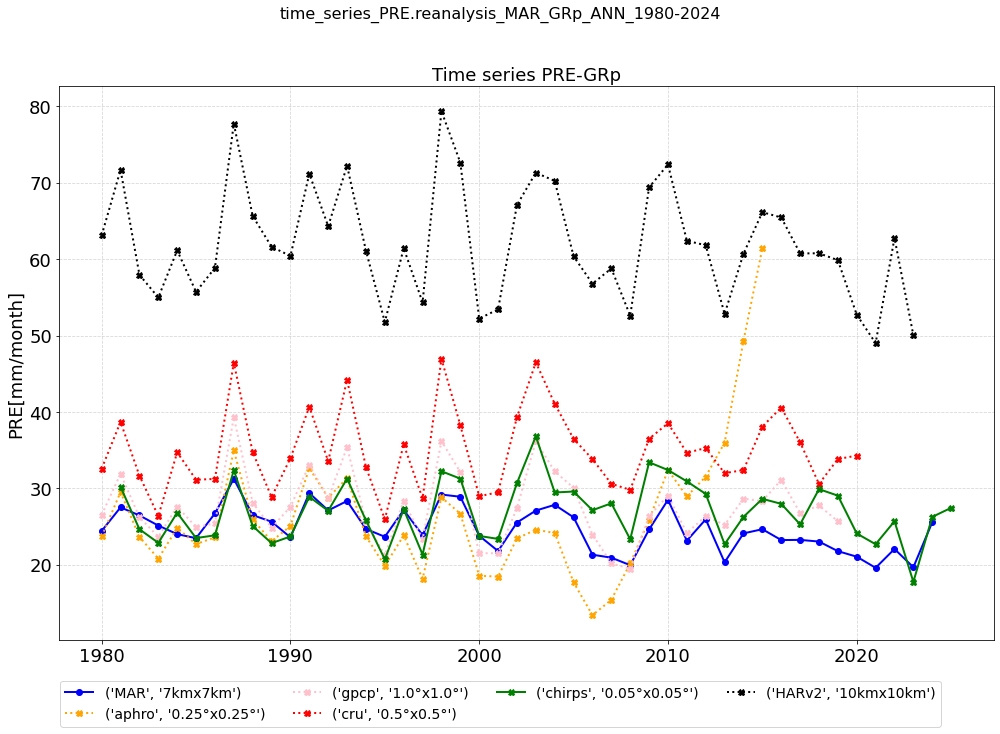

/home/santolam/RECAP/figures/time_series_PRE.reanalysis_MAR_GRp_ANN_1980-2024.png
[24.70127296447754, 26.46345518850531, 27.544652938842773, 35.01810836791992, 26.959749221801758, 61.985704516229845]
[2.805535078048706, 8.861551866007117, 4.457123756408691, 5.186820030212402, 3.8346781730651855, 7.405528464420973]


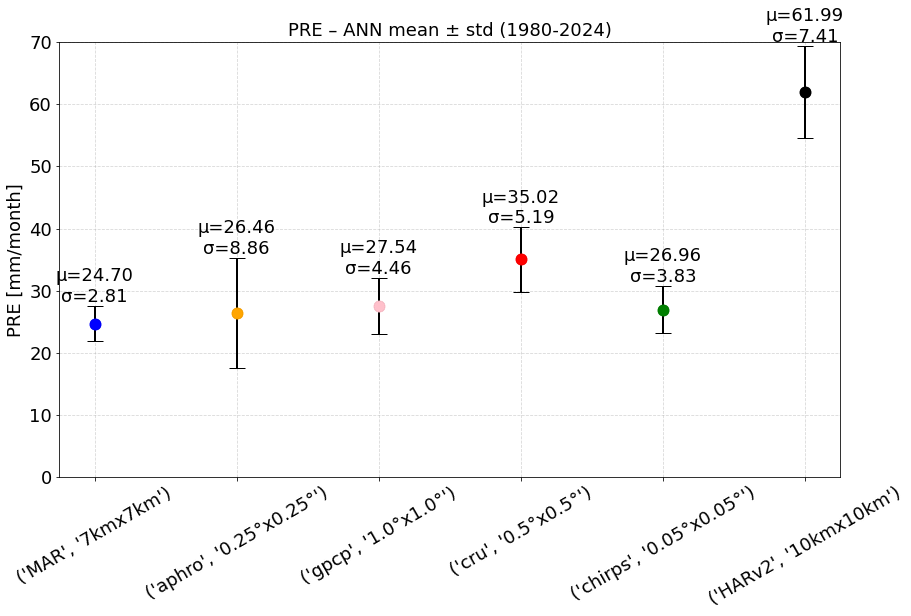

/home/santolam/RECAP/figures/mean_stddev_PRE.reanalysis_MAR_GRp_ANN_1980-2024.png


In [40]:
season=seasonList[4]
print(season)
field1_season = field1_season_all.sel(season=season)
field3_season = field3_season_all.sel(season=season)
field4_season = field4_season_all.sel(season=season)
field5_season = field5_season_all.sel(season=season)
field6_season = field6_season_all.sel(season=season)
field7_season = field7_season_all.sel(season=season)

# Then apply it like this:
ts_mean_vals_field1 = field1_season.mean(dim=['X', 'Y'])
ts_mean_vals_field3 = field3_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field4= field4_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field5= field5_season.mean(dim= ['lon', 'lat'])
ts_mean_vals_field6= field6_season.mean(dim=['lon', 'lat'])
ts_mean_vals_field7 = field7_season.mean(dim=  ['south_north', 'west_east'])

colorList=['b','orange', 'pink', 'red', 'green','black']
markerList=['o','X','X','X','X','X','X']#

plotname=f'time_series_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

colors = colorList

fig, ax= plt.subplots(figsize=(14, 10), sharex=False, sharey=False)

# Plot one line per dataset
ax.plot(ts_mean_vals_field1.year, ts_mean_vals_field1.values, 'o', linestyle='-',label=nameList[0], color=colors[0], linewidth=2)
ax.plot(ts_mean_vals_field3.year, ts_mean_vals_field3.values,marker=markerList[1], linestyle=':',label=nameList[1], color=colors[1], linewidth=2)
ax.plot(ts_mean_vals_field4.year, ts_mean_vals_field4.values,marker=markerList[2],linestyle=':',label=nameList[2], color=colors[2], linewidth=2)
ax.plot(ts_mean_vals_field5.year,ts_mean_vals_field5.values, marker=markerList[3],linestyle=':',label=nameList[3], color=colors[3], linewidth=2)
ax.plot(ts_mean_vals_field6.year ,ts_mean_vals_field6.values,marker=markerList[4],linestyle='-',label=nameList[4], color=colors[4], linewidth=2)    
ax.plot(ts_mean_vals_field7.year,ts_mean_vals_field7.values, marker=markerList[5],linestyle=':',label=nameList[5], color=colors[5], linewidth=2)

ax.set_title(f'Time series PRE-{domainM}', fontsize=18)
#ax.set_xticks(months)
ax.set_ylabel(f'{var}[{units}]', fontsize=18)
#years=ac_mean_vals_field1[0].year.values
#xticks = years[::2]
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)

ax.grid(True, linestyle='--', alpha=0.5)

# Axis labels and legend
fig.suptitle(plotname, fontsize=16)
#fig.supxlabel('Month', fontsize=14)
#fig.supylabel('Snow Height [m]', fontsize=14)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.03),
    ncol=4,
    fontsize=14,
    frameon=True
)

# Adjust layout and save with full legend
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
#plt.savefig(plotsDir + 'monthly_snowheight_by_elevation.png', , dpi=300)

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')


datasets = [
    ts_mean_vals_field1,
    ts_mean_vals_field3,
    ts_mean_vals_field4,
    ts_mean_vals_field5,
    ts_mean_vals_field6,
    ts_mean_vals_field7,
]

dataset_names = nameList  # same order
colors = colorList

means = [ds.mean(dim='year').values.item() for ds in datasets]
stds  = [ds.std(dim='year').values.item() for ds in datasets]
print(means)
print(stds)
plotname=f'mean_stddev_{var}.reanalysis_MAR_{domainM}_{season}_{str(iyr)}-{str(fyr)}'

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(dataset_names))

ax.errorbar(
    x, means, yerr=stds,
    fmt='o',
    capsize=8,
    markersize=10,
    linewidth=2,
    color='black'
)

# Color individual points
for xi, mu, color in zip(x, means, colors):
    ax.scatter(xi, mu, color=color, s=120, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(dataset_names, rotation=30,fontsize=18)
ax.set_ylabel(f'{var} [{units}]',fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.tick_params(axis='x', labelsize=18)
ax.set_ylim(0,70)
ax.set_title(f'{var} – {season} mean ± std ({iyr}-{fyr})',fontsize=18)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate
for xi, mu, sigma in zip(x, means, stds):
    ax.text(
        xi, mu + sigma,
        f'μ={mu:.2f}\nσ={sigma:.2f}',
        ha='center',
        va='bottom',
        fontsize=18
    )

# Save figure (including legend outside)
plt.savefig(plotsDir+plotname+'.png', bbox_inches='tight')
plt.show()
print(plotsDir+plotname+'.png')